# 03 - BPR-MF parameter study

**Owner:** Member 2
**Task:** Vary embedding dimension (16/32/64/128), learning rate and L2 for BPR-MF on KuaiRand-Pure and KuaiRec. Select the best setting per dataset on validation Recall@20 only (seed 0, see the compute budget in CLAUDE.md). The grid must have the same size as LightGCN's in notebook 04. Report the unbiased test of the selected setting only; never use it to choose.
**Inputs:** src/data/, src/models/, src/training/
**Outputs:** results/03_mf_parameters.json (every run, plus the selected setting per dataset)

After running: save the numbers to `results/`, append an entry to `LOG.md`, and write the matching report section.

In [3]:
import os, sys, json
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import data
import models
import training
import inference

SEEDS = [0, 1, 2]
RESULTS_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "results"))
os.makedirs(RESULTS_DIR, exist_ok=True)


## 1. Load the processed datasets

In [5]:
datasets = {
    "kuairand": data.load_processed("kuairand", seed=0),
    "kuairec": data.load_processed("kuairec", seed=0),
}

for name, ds in datasets.items():
    print(
        name,
        "| users:", ds["n_users"],
        "| items:", ds["n_items"],
        "| train interactions:", sum(len(items) for items in ds["train"].values()),
    )

kuairand | users: 25689 | items: 7218 | train interactions: 466490
kuairec | users: 7173 | items: 10611 | train interactions: 609375


## 2. BPR-MF and the shared training loop

BPR-MF gives every user and video an embedding. Its score for a user-video pair is their dot product. During training, it samples one observed positive video and one unobserved video, then learns to rank the positive one higher.

This is the non-graph control: it uses the same BPR loss, negative sampling, split, evaluator and early stopping as LightGCN, but it does **not** propagate information through the user-item graph. In the configuration dictionary, `reg` is the coefficient of the L2 regularisation term.

In [16]:
TUNING_SEED = 0
RUN_SANITY = False
SANITY_DATASET = "kuairand"
RUN_FULL_STUDY = False
RUN_FINAL_EVALUATION = False
RESULT_PATH = os.path.join(RESULTS_DIR, "03_mf_parameters.json")

BASE_CONFIG = {
    "model": "mf",
    "dim": 64,
    "lr": 1e-3,
    "reg": 1e-4,
    "batch": 2048,
    "epochs": 100,
    "threads": 8,
}

def completed_epochs(out):
    return max(row["epoch"] for row in out["history"])

def validation_summary(out):
    epochs = completed_epochs(out)
    return pd.Series({
        "validation Recall@20": out["val_recall"],
        "best epoch": out["best_epoch"],
        "epochs completed": epochs,
        "end-to-end seconds": out["train_time"],
        "seconds per completed epoch": out["train_time"] / epochs,
    })

pd.Series(BASE_CONFIG, name="baseline configuration")

model          mf
dim            64
lr          0.001
reg        0.0001
batch        2048
epochs        100
threads         8
Name: baseline configuration, dtype: object

## 3. One-run sanity check

Before a multi-run study, train the baseline once. This checks processed-data loading, BPR loss, negative sampling, early stopping and validation evaluation together.

Set `RUN_SANITY = True` above and keep `SANITY_DATASET = "kuairand"` for the first run. This cell deliberately shows validation behaviour only; do not inspect test metrics while tuning.

In [7]:
if RUN_SANITY:
    sanity_out, _, _, _ = training.fit(
        BASE_CONFIG,
        datasets[SANITY_DATASET],
        seed=TUNING_SEED,
        verbose=True,
        eval_every=5,
        patience=4,
    )
    display(validation_summary(sanity_out))
    display(pd.DataFrame(sanity_out["history"]).tail(10))
else:
    print("Sanity run is disabled. Set RUN_SANITY = True after checking the data above.")

ep 5 loss 0.4449 val_recall 0.0997 (19s)
ep 10 loss 0.1993 val_recall 0.1345 (41s)
ep 15 loss 0.1324 val_recall 0.1496 (59s)
ep 20 loss 0.0985 val_recall 0.1541 (78s)
ep 25 loss 0.0781 val_recall 0.1560 (101s)
ep 30 loss 0.0650 val_recall 0.1564 (120s)
ep 35 loss 0.0549 val_recall 0.1580 (141s)
ep 40 loss 0.0480 val_recall 0.1582 (159s)
ep 45 loss 0.0426 val_recall 0.1592 (182s)
ep 50 loss 0.0385 val_recall 0.1614 (203s)
ep 55 loss 0.0358 val_recall 0.1590 (223s)
ep 60 loss 0.0326 val_recall 0.1578 (246s)
ep 65 loss 0.0295 val_recall 0.1572 (265s)
ep 70 loss 0.0282 val_recall 0.1586 (284s)


validation Recall@20             0.161391
best epoch                      50.000000
epochs completed                70.000000
end-to-end seconds             287.490228
seconds per completed epoch      4.107003
dtype: float64

,epoch,loss,time,val_recall
60,61,0.031923,252.621298,NaN
61,62,0.031893,255.823942,NaN
62,63,0.030837,259.030337,NaN
63,64,0.030359,262.081706,NaN
64,65,0.029474,264.963835,0.157206
65,66,0.029605,271.557521,NaN
66,67,0.029683,274.719000,NaN
67,68,0.028626,277.770515,NaN
68,69,0.028472,280.794771,NaN
69,70,0.028193,283.973189,0.158569


## 4. Tuning configurations

The proposed one-factor-at-a-time study has eight configurations per dataset: the baseline, all remaining required embedding dimensions, two learning-rate alternatives and two L2 alternatives. Every listed configuration is an actual candidate for selection; do not create an untested mixture of separately good settings.

This list uses the shared budget of eight configurations per dataset. If the team later changes that budget, update this list **before** starting the full sweep.

In [9]:
CONFIGS = [
    {**BASE_CONFIG, "label": "baseline"},
    {**BASE_CONFIG, "label": "dim_16", "dim": 16},
    {**BASE_CONFIG, "label": "dim_32", "dim": 32},
    {**BASE_CONFIG, "label": "dim_128", "dim": 128},
    {**BASE_CONFIG, "label": "lr_3e-4", "lr": 3e-4},
    {**BASE_CONFIG, "label": "lr_3e-3", "lr": 3e-3},
    {**BASE_CONFIG, "label": "reg_1e-5", "reg": 1e-5},
    {**BASE_CONFIG, "label": "reg_1e-3", "reg": 1e-3},
]

assert {cfg["dim"] for cfg in CONFIGS} == {16, 32, 64, 128}
assert all(cfg["model"] == "mf" for cfg in CONFIGS)

pd.DataFrame(CONFIGS).set_index("label")

,model,dim,lr,reg,batch,epochs,threads
label,,,,,,,
baseline,mf,64,0.0010,0.00010,2048,100,8
dim_16,mf,16,0.0010,0.00010,2048,100,8
dim_32,mf,32,0.0010,0.00010,2048,100,8
dim_128,mf,128,0.0010,0.00010,2048,100,8
lr_3e-4,mf,64,0.0003,0.00010,2048,100,8
lr_3e-3,mf,64,0.0030,0.00010,2048,100,8
reg_1e-5,mf,64,0.0010,0.00001,2048,100,8
reg_1e-3,mf,64,0.0010,0.00100,2048,100,8


## 5. Train and Validation Study

The runner writes a small progress record after every completed configuration. 
If a run is interrupted, rerunning it skips the same dataset/configuration pair.

For each tuning run, it saves the configuration, validation Recall@20, early-stopping epoch and timing. The shared training function computes test metrics at the end, but this section deliberately does not display or save them for parameter selection.

In [10]:
CONFIG_FIELDS = ("model", "dim", "lr", "reg", "batch", "epochs", "threads")

def config_signature(cfg):
    return json.dumps({k: cfg[k] for k in CONFIG_FIELDS}, sort_keys=True)

def empty_results():
    return {
        "protocol": {
            "tuning_seed": TUNING_SEED,
            "selection_metric": "validation Recall@20",
            "standard_test_used_for_selection": False,
            "less_biased_test_used_for_selection": False,
        },
        "runs": [],
    }

def load_results():
    if not os.path.exists(RESULT_PATH):
        return empty_results()
    with open(RESULT_PATH) as f:
        return json.load(f)

def save_results(payload):
    with open(RESULT_PATH, "w") as f:
        json.dump(payload, f, indent=2)

def current_records(payload):
    signatures = {config_signature(cfg) for cfg in CONFIGS}
    return [
        row for row in payload.get("runs", [])
        if row["dataset"] in datasets and row["signature"] in signatures
    ]

def run_parameter_study():
    payload = load_results()
    completed = {(row["dataset"], row["signature"]) for row in payload.get("runs", [])}

    for dataset_name, ds in datasets.items():
        for cfg in CONFIGS:
            signature = config_signature(cfg)
            if (dataset_name, signature) in completed:
                print(f"Skipping completed run: {dataset_name} / {cfg['label']}")
                continue

            print(f"Running {dataset_name} / {cfg['label']}", flush=True)
            out, _, _, _ = training.fit(
                cfg, ds, seed=TUNING_SEED, verbose=True, eval_every=5, patience=4
            )
            epochs = completed_epochs(out)
            payload["runs"].append({
                "dataset": dataset_name,
                "label": cfg["label"],
                "signature": signature,
                "config": {k: cfg[k] for k in CONFIG_FIELDS},
                "val_recall": float(out["val_recall"]),
                "best_epoch": int(out["best_epoch"]),
                "epochs_completed": int(epochs),
                "train_time_seconds": float(out["train_time"]),
                "seconds_per_completed_epoch": float(out["train_time"] / epochs),
            })
            save_results(payload)

    return payload

def make_tuning_table(payload):
    table = pd.DataFrame(current_records(payload))
    if table.empty:
        return table
    return table.sort_values(["dataset", "val_recall"], ascending=[True, False]).reset_index(drop=True)

In [11]:
if RUN_FULL_STUDY:
    results_payload = run_parameter_study()
    tuning_table = make_tuning_table(results_payload)
    display(tuning_table)
else:
    results_payload = load_results()
    tuning_table = make_tuning_table(results_payload)
    print("Full study is disabled. Set RUN_FULL_STUDY = True when you are ready to run it.")
    if not tuning_table.empty:
        display(tuning_table)

Running kuairand / baseline
ep 5 loss 0.4449 val_recall 0.0997 (17s)
ep 10 loss 0.1993 val_recall 0.1345 (42s)
ep 15 loss 0.1324 val_recall 0.1496 (62s)
ep 20 loss 0.0985 val_recall 0.1541 (81s)
ep 25 loss 0.0781 val_recall 0.1560 (99s)
ep 30 loss 0.0650 val_recall 0.1564 (121s)
ep 35 loss 0.0549 val_recall 0.1580 (143s)
ep 40 loss 0.0480 val_recall 0.1582 (162s)
ep 45 loss 0.0426 val_recall 0.1592 (183s)
ep 50 loss 0.0385 val_recall 0.1614 (203s)
ep 55 loss 0.0358 val_recall 0.1590 (223s)
ep 60 loss 0.0326 val_recall 0.1578 (245s)
ep 65 loss 0.0295 val_recall 0.1572 (269s)
ep 70 loss 0.0282 val_recall 0.1586 (289s)
Running kuairand / dim_16
ep 5 loss 0.5842 val_recall 0.0850 (7s)
ep 10 loss 0.2724 val_recall 0.1199 (17s)
ep 15 loss 0.2171 val_recall 0.1319 (27s)
ep 20 loss 0.1818 val_recall 0.1387 (37s)
ep 25 loss 0.1545 val_recall 0.1456 (46s)
ep 30 loss 0.1369 val_recall 0.1488 (56s)
ep 35 loss 0.1217 val_recall 0.1513 (65s)
ep 40 loss 0.1114 val_recall 0.1543 (75s)
ep 45 loss 0.103

,dataset,label,signature,config,val_recall,best_epoch,epochs_completed,train_time_seconds,seconds_per_completed_epoch
0,kuairand,reg_1e-3,"{""batch"": 2048, ""dim"": 64, ""epochs"": 100, ""lr""...","{'model': 'mf', 'dim': 64, 'lr': 0.001, 'reg':...",0.167303,100,100,710.254836,7.102548
1,kuairand,dim_16,"{""batch"": 2048, ""dim"": 16, ""epochs"": 100, ""lr""...","{'model': 'mf', 'dim': 16, 'lr': 0.001, 'reg':...",0.163187,85,100,197.484814,1.974848
2,kuairand,baseline,"{""batch"": 2048, ""dim"": 64, ""epochs"": 100, ""lr""...","{'model': 'mf', 'dim': 64, 'lr': 0.001, 'reg':...",0.161391,50,70,292.226057,4.174658
3,kuairand,reg_1e-5,"{""batch"": 2048, ""dim"": 64, ""epochs"": 100, ""lr""...","{'model': 'mf', 'dim': 64, 'lr': 0.001, 'reg':...",0.161097,50,70,245.266832,3.503812
4,kuairand,dim_32,"{""batch"": 2048, ""dim"": 32, ""epochs"": 100, ""lr""...","{'model': 'mf', 'dim': 32, 'lr': 0.001, 'reg':...",0.160874,50,70,201.657463,2.880821
5,kuairand,lr_3e-4,"{""batch"": 2048, ""dim"": 64, ""epochs"": 100, ""lr""...","{'model': 'mf', 'dim': 64, 'lr': 0.0003, 'reg'...",0.158047,100,100,603.034438,6.030344
6,kuairand,dim_128,"{""batch"": 2048, ""dim"": 128, ""epochs"": 100, ""lr...","{'model': 'mf', 'dim': 128, 'lr': 0.001, 'reg'...",0.157568,35,55,303.326344,5.515024
7,kuairand,lr_3e-3,"{""batch"": 2048, ""dim"": 64, ""epochs"": 100, ""lr""...","{'model': 'mf', 'dim': 64, 'lr': 0.003, 'reg':...",0.155284,15,35,124.822605,3.566360
8,kuairec,lr_3e-4,"{""batch"": 2048, ""dim"": 64, ""epochs"": 100, ""lr""...","{'model': 'mf', 'dim': 64, 'lr': 0.0003, 'reg'...",0.108421,75,95,489.310360,5.150635
9,kuairec,baseline,"{""batch"": 2048, ""dim"": 64, ""epochs"": 100, ""lr""...","{'model': 'mf', 'dim': 64, 'lr': 0.001, 'reg':...",0.107365,25,45,261.962592,5.821391


## 6. Select by validation Recall@20

For each dataset, the selected configuration is the row with the largest validation Recall@20. This cell checks that all current configurations have completed before choosing. Standard-test and less-biased-test values play no role here.

In [13]:
def select_configs(tuning_table):
    selected = []
    for dataset_name in datasets:
        rows = tuning_table[tuning_table["dataset"] == dataset_name]
        if len(rows) != len(CONFIGS):
            raise RuntimeError(
                f"{dataset_name} has {len(rows)} completed configurations; expected {len(CONFIGS)}."
            )
        selected.append(rows.loc[rows["val_recall"].idxmax()].to_dict())
    return pd.DataFrame(selected).set_index("dataset")

if len(tuning_table) == len(datasets) * len(CONFIGS):
    selected_table = select_configs(tuning_table)
    # Save the validation-selected settings before looking at either test set.
    results_payload["selected"] = selected_table.reset_index().to_dict(orient="records")
    save_results(results_payload)
    display(selected_table[["label", "config", "val_recall", "best_epoch", "train_time_seconds"]])
else:
    selected_table = None
    print("Selection will be available after every current configuration has completed.")

,label,config,val_recall,best_epoch,train_time_seconds
dataset,,,,,
kuairand,reg_1e-3,"{'model': 'mf', 'dim': 64, 'lr': 0.001, 'reg':...",0.167303,100,710.254836
kuairec,lr_3e-4,"{'model': 'mf', 'dim': 64, 'lr': 0.0003, 'reg'...",0.108421,75,489.310360


## 7. Final evaluation of selected configurations

After selection, this cell retrains each selected configuration once with the same seed and reports both test sets. This is the first point in the notebook where test metrics are displayed and saved.

For KuaiRec's less-biased test, Recall@20 has a low ceiling because each user has many positives. Interpret NDCG@20 alongside Recall@20.

In [15]:
if RUN_FINAL_EVALUATION:
    if selected_table is None:
        raise RuntimeError("Complete the validation study and select configurations before final evaluation.")

    final_evaluations = {}
    for dataset_name, row in selected_table.iterrows():
        cfg = {**row["config"], "label": row["label"]}
        print(f"Final evaluation: {dataset_name} / {cfg['label']}", flush=True)
        out, _, _, _ = training.fit(
            cfg, datasets[dataset_name], seed=TUNING_SEED, verbose=True, eval_every=5, patience=4
        )
        final_evaluations[dataset_name] = {
            "label": cfg["label"],
            "config": {k: cfg[k] for k in CONFIG_FIELDS},
            "val_recall": float(out["val_recall"]),
            "best_epoch": int(out["best_epoch"]),
            "train_time_seconds": float(out["train_time"]),
            "standard_test": out["test"],
            "less_biased_test": out["test_unbiased"],
        }

    results_payload["selected"] = selected_table.reset_index().to_dict(orient="records")
    results_payload["final_evaluations"] = final_evaluations
    save_results(results_payload)
    display(pd.DataFrame({
        name: {
            "validation Recall@20": row["val_recall"],
            "standard Recall@20": row["standard_test"]["recall"],
            "standard NDCG@20": row["standard_test"]["ndcg"],
            "less-biased Recall@20": row["less_biased_test"]["recall"],
            "less-biased NDCG@20": row["less_biased_test"]["ndcg"],
        }
        for name, row in final_evaluations.items()
    }).T)
else:
    print("Final evaluation is disabled. Set RUN_FINAL_EVALUATION = True only after validation-based selection.")

Final evaluation: kuairand / reg_1e-3
ep 5 loss 0.4459 val_recall 0.1000 (17s)
ep 10 loss 0.2006 val_recall 0.1354 (37s)
ep 15 loss 0.1342 val_recall 0.1504 (61s)
ep 20 loss 0.1007 val_recall 0.1545 (81s)
ep 25 loss 0.0805 val_recall 0.1565 (98s)
ep 30 loss 0.0678 val_recall 0.1584 (116s)
ep 35 loss 0.0578 val_recall 0.1600 (135s)
ep 40 loss 0.0511 val_recall 0.1612 (153s)
ep 45 loss 0.0458 val_recall 0.1631 (170s)
ep 50 loss 0.0417 val_recall 0.1650 (188s)
ep 55 loss 0.0392 val_recall 0.1639 (205s)
ep 60 loss 0.0361 val_recall 0.1631 (223s)
ep 65 loss 0.0330 val_recall 0.1632 (244s)
ep 70 loss 0.0318 val_recall 0.1652 (263s)
ep 75 loss 0.0299 val_recall 0.1640 (282s)
ep 80 loss 0.0293 val_recall 0.1651 (301s)
ep 85 loss 0.0276 val_recall 0.1642 (320s)
ep 90 loss 0.0268 val_recall 0.1665 (339s)
ep 95 loss 0.0258 val_recall 0.1666 (357s)
ep 100 loss 0.0250 val_recall 0.1673 (377s)
Final evaluation: kuairec / lr_3e-4
ep 5 loss 0.6813 val_recall 0.0042 (14s)
ep 10 loss 0.4741 val_recall 0

,validation Recall@20,standard Recall@20,standard NDCG@20,less-biased Recall@20,less-biased NDCG@20
kuairand,0.167303,0.169338,0.110201,0.006033,0.004080
kuairec,0.108421,0.106590,0.114497,0.173128,0.563071


## 8. Validation figure

This figure visualises validation Recall@20 for the completed BPR-MF configurations.

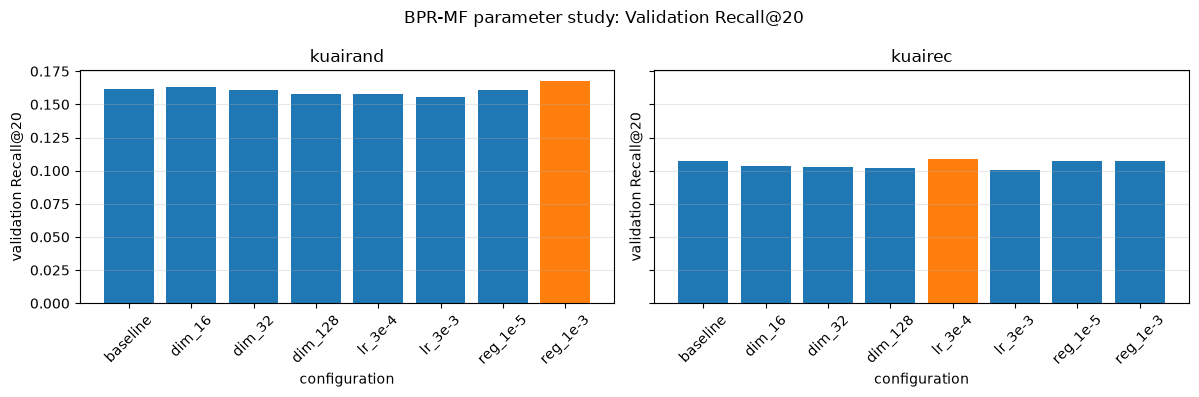

In [18]:
CONFIG_ORDER = [
    "baseline",
    "dim_16",
    "dim_32",
    "dim_128",
    "lr_3e-4",
    "lr_3e-3",
    "reg_1e-5",
    "reg_1e-3",
]

if selected_table is not None:
    fig, axes = plt.subplots(1, len(datasets), figsize=(12, 4), sharey=True)
    if len(datasets) == 1:
        axes = [axes]

    order_map = {label: position for position, label in enumerate(CONFIG_ORDER)}

    for ax, dataset_name in zip(axes, datasets):
        rows = tuning_table[tuning_table["dataset"] == dataset_name].copy()
        rows["_plot_order"] = rows["label"].map(order_map)
        rows = rows.sort_values("_plot_order", kind="stable")

        selected_label = selected_table.loc[dataset_name, "label"]
        colors = [
            "tab:orange" if label == selected_label else "tab:blue"
            for label in rows["label"]
        ]

        ax.bar(rows["label"], rows["val_recall"], color=colors)
        ax.set_title(dataset_name)
        ax.set_xlabel("configuration")
        ax.set_ylabel("validation Recall@20")
        ax.tick_params(axis="x", rotation=45)
        ax.grid(axis="y", alpha=0.3)

    fig.suptitle("BPR-MF parameter study: Validation Recall@20")
    fig.tight_layout()
    fig.savefig(
        os.path.join(RESULTS_DIR, "03_mf_validation.png"),
        dpi=200,
        metadata={"Software": None},
    )
    plt.show()
else:
    print("The validation figure is available after the full study has completed and selected settings exist.")